##Identifying Data Quality Issues & Data Cleaning


In [616]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [617]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

In [618]:
data = pd.read_excel("/content/drive/MyDrive/FinSightAssessment/Working Files /Raw_data.xlsx")

In [619]:
data.head()

,Customer_ID,Full_Name,NIC_Number,Gender,Date_of_Birth,Age,District,Province,Urban_Rural,Customer_Segment,...,PEP_Flag,Has_Fixed_Deposit,FD_Amount,Has_Insurance,Has_Mobile_Wallet,Number_of_Products,Acquisition_Channel,Referral_Source,Last_Campaign_Response,Promo_Code_Used
0,FSL-0001,Mark Johnson,808614657V,Female,1980-12-26,43,Kandy,Central,Suburban,Regular,...,No,No,NaN,No,Yes,2,Referral,Friend,Responded,Yes
1,FSL-0002,Deborah Phillips,718478527V,Female,1971-12-13,52,Badulla,Uva,Urban,Starter,...,No,No,NaN,No,Yes,2,Referral,Family,Ignored,No
2,FSL-0003,Charles Phillips,933515010V,Male,1993-12-17,30,Kandy,Central,Suburban,Regular,...,No,Yes,1166599.45,No,No,3,Agent,Colleague,Responded,No
3,FSL-0004,Rachel Hall,720422796V,Male,1972-02-11,51,Kandy,Central,Suburban,Regular,...,No,Yes,1051113.61,Yes,No,4,Referral,NaN,Ignored,Yes
4,FSL-0005,Sharon Bell,940729689V,Male,1994-03-13,29,Colombo,Western,Suburban,Regular,...,No,No,NaN,No,Yes,3,Referral,NaN,Unsubscribed,No


In [620]:
data.columns

Index(['Customer_ID', 'Full_Name', 'NIC_Number', 'Gender', 'Date_of_Birth',
       'Age', 'District', 'Province', 'Urban_Rural', 'Customer_Segment',
       'Account_Open_Date', 'Customer_Tenure_Years', 'Savings_Balance',
       'Monthly_Deposit_Avg', 'Monthly_Withdrawal_Avg', 'Net_Monthly_Flow',
       'Account_Status', 'Interest_Rate_Tier', 'Has_Loan', 'Loan_Type',
       'Loan_Amount', 'Loan_Tenure_Months', 'Monthly_Repayment_Amount',
       'Loan_Repayment_Status', 'Loan_Start_Date', 'Outstanding_Loan_Balance',
       'Mobile_App_User', 'Last_Login_Date', 'Monthly_Transaction_Count',
       'Preferred_Channel', 'Push_Notification_Enabled', 'KYC_Status',
       'KYC_Last_Updated', 'Suspicious_Activity_Flag', 'PEP_Flag',
       'Has_Fixed_Deposit', 'FD_Amount', 'Has_Insurance', 'Has_Mobile_Wallet',
       'Number_of_Products', 'Acquisition_Channel', 'Referral_Source',
       'Last_Campaign_Response', 'Promo_Code_Used'],
      dtype='object')

In [621]:
data.describe()

,Date_of_Birth,Age,Account_Open_Date,Customer_Tenure_Years,Savings_Balance,Monthly_Deposit_Avg,Monthly_Withdrawal_Avg,Net_Monthly_Flow,Loan_Amount,Loan_Tenure_Months,Monthly_Repayment_Amount,Loan_Start_Date,Outstanding_Loan_Balance,Last_Login_Date,Monthly_Transaction_Count,KYC_Last_Updated,FD_Amount,Number_of_Products
count,508,508.000000,508,508.000000,5.020000e+02,502.000000,5.080000e+02,508.000000,2.170000e+02,218.00000,218.000000,220,2.190000e+02,339,508.000000,508,1.500000e+02,508.000000
mean,1986-11-01 10:37:47.716535424,37.005906,2019-07-29 12:42:31.181102592,4.450394,2.751256e+06,37871.756454,5.900753e+04,15896.003681,1.427319e+06,34.12844,66446.899312,2021-09-13 16:34:54.545454592,7.671478e+05,2023-09-28 12:19:06.902654976,12.844488,2022-01-23 04:46:17.952755968,1.072150e+06,2.501969
min,1890-03-11 00:00:00,4.000000,2015-01-14 00:00:00,0.000000,-8.800000e+04,194.790000,1.009900e+02,30.870000,5.430853e+04,12.00000,1008.140000,2008-03-20 00:00:00,1.625884e+04,2023-06-01 00:00:00,0.000000,2020-01-07 00:00:00,1.132178e+05,1.000000
25%,1978-06-15 18:00:00,28.000000,2017-02-04 18:00:00,2.200000,1.206972e+05,5607.160000,3.230255e+03,1850.815000,7.088174e+05,12.00000,20592.450000,2020-08-01 00:00:00,2.309473e+05,2023-08-02 00:00:00,3.000000,2021-01-29 18:00:00,6.126846e+05,2.000000
50%,1987-01-15 12:00:00,36.500000,2019-09-05 00:00:00,4.300000,4.427638e+05,17694.735000,9.684800e+03,5851.795000,1.421378e+06,36.00000,47278.575000,2022-06-26 00:00:00,6.695107e+05,2023-09-21 00:00:00,10.000000,2021-12-25 00:00:00,1.094277e+06,2.000000
75%,1995-06-16 00:00:00,45.000000,2021-10-21 18:00:00,6.900000,7.290134e+05,39642.022500,2.288924e+04,16963.655000,2.114078e+06,48.00000,82529.862500,2023-06-03 00:00:00,1.189685e+06,2023-11-11 00:00:00,22.000000,2023-02-25 18:00:00,1.500871e+06,3.000000
max,2020-05-01 00:00:00,150.000000,2026-06-01 00:00:00,9.000000,1.000000e+09,347140.120000,9.999999e+06,196240.990000,2.998363e+06,60.00000,274849.530000,2023-12-31 00:00:00,2.460698e+06,2027-01-01 00:00:00,35.000000,2024-01-01 00:00:00,1.977886e+06,6.000000
std,NaN,12.132973,NaN,2.635717,4.461133e+07,57934.118045,5.926862e+05,26785.955644,8.472906e+05,17.48474,64127.945546,NaN,5.918506e+05,NaN,10.856125,NaN,5.349633e+05,0.941062


In [622]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 508 entries, 0 to 507
Data columns (total 44 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Customer_ID                508 non-null    object        
 1   Full_Name                  500 non-null    object        
 2   NIC_Number                 508 non-null    object        
 3   Gender                     508 non-null    object        
 4   Date_of_Birth              508 non-null    datetime64[ns]
 5   Age                        508 non-null    int64         
 6   District                   503 non-null    object        
 7   Province                   508 non-null    object        
 8   Urban_Rural                508 non-null    object        
 9   Customer_Segment           503 non-null    object        
 10  Account_Open_Date          508 non-null    datetime64[ns]
 11  Customer_Tenure_Years      508 non-null    float64       
 12  Savings_

###Issue 01- Redundant Exact Duplicate Customer Records

In [623]:
#identifying full duplicates
data.duplicated().sum()
data[data.duplicated(keep=False)]

,Customer_ID,Full_Name,NIC_Number,Gender,Date_of_Birth,Age,District,Province,Urban_Rural,Customer_Segment,...,PEP_Flag,Has_Fixed_Deposit,FD_Amount,Has_Insurance,Has_Mobile_Wallet,Number_of_Products,Acquisition_Channel,Referral_Source,Last_Campaign_Response,Promo_Code_Used
10,FSL-0011,Joshua Mitchell,862063426V,Male,1986-07-25,37,Kurunegala,North Western,Urban,Regular,...,No,No,NaN,Yes,No,2,Referral,NaN,Ignored,No
45,FSL-0046,Nicole Morris,012378685V,Male,2001-08-25,22,Ratnapura,Sabaragamuwa,Suburban,Starter,...,No,Yes,1819779.08,No,Yes,3,Branch,NaN,Responded,No
280,FSL-0281,Linda Scott,916433090V,Female,1991-05-23,32,Matara,Southern,Urban,Regular,...,No,Yes,912753.66,No,No,2,Branch,Colleague,Ignored,Yes
500,FSL-0011,Joshua Mitchell,862063426V,Male,1986-07-25,37,Kurunegala,North Western,Urban,Regular,...,No,No,NaN,Yes,No,2,Referral,NaN,Ignored,No
501,FSL-0046,Nicole Morris,012378685V,Male,2001-08-25,22,Ratnapura,Sabaragamuwa,Suburban,Starter,...,No,Yes,1819779.08,No,Yes,3,Branch,NaN,Responded,No
505,FSL-0281,Linda Scott,916433090V,Female,1991-05-23,32,Matara,Southern,Urban,Regular,...,No,Yes,912753.66,No,No,2,Branch,Colleague,Ignored,Yes


In [624]:
#drop one record of fully duplicated pairs
data = data.drop_duplicates()
data.duplicated().sum()

np.int64(0)

###Issue 02- Duplicate Customer_ID and NICs

####Instances of duplicate Customer_IDs

In [625]:
#All instances of duplicate Customer_IDs
num_dup_ids = data['Customer_ID'].duplicated().sum()
print(f"Number of duplicate Customer_IDs: {num_dup_ids}")

duplicate_ids = data[data['Customer_ID'].duplicated(keep=False)].sort_values('Customer_ID')
print(duplicate_ids[['Customer_ID', 'Full_Name', 'NIC_Number', 'Account_Open_Date','Age',"KYC_Status","Gender"]])

Number of duplicate Customer_IDs: 5
    Customer_ID           Full_Name  NIC_Number Account_Open_Date  Age  \
88     FSL-0089  Catherine Mitchell  821642369V        2016-09-28  134   
502    FSL-0089  Catherine Mitchell  821642369V        2016-09-28   41   
130    FSL-0131         Ryan Torres  992664913V        2016-07-28   24   
503    FSL-0131         Ryan Torres  992664913V        2016-07-28   24   
200    FSL-0201       Nancy Johnson  821599078V        2020-05-22   41   
504    FSL-0201       Nancy Johnson  821599078V        2020-05-22   41   
350    FSL-0351      Charles Morgan  850611344V        2018-07-24   52   
506    FSL-0351      Charles Morgan  717648100V        2018-07-24   52   
420    FSL-0421      Nicole Roberts  918354937V        2020-07-02   41   
507    FSL-0421      Nicole Roberts  827457336V        2020-07-02   41   

    KYC_Status  Gender  
88    Verified    Male  
502   Verified    Male  
130        NaN    Male  
503    Pending    Male  
200   Verified    Male  

In [626]:
#Fixing the primary id violation

data = data.drop(index=[88, 130, 504, 350, 420])
data.loc[[507, 506], "NIC_Number"] = np.nan


####Instances of duplicate NICs

In [627]:
#All instances of duplicate NICs

num_dup_nics = data['NIC_Number'].duplicated().sum()
print(f"Number of duplicate NIC_Numbers: {num_dup_nics}")

duplicate_nics = data[data['NIC_Number'].duplicated(keep=False)].sort_values('NIC_Number')
print(duplicate_nics[['Customer_ID', 'Full_Name', 'NIC_Number', 'Account_Open_Date',"KYC_Status"]])

Number of duplicate NIC_Numbers: 2
    Customer_ID       Full_Name  NIC_Number Account_Open_Date KYC_Status
75     FSL-0076   Nancy Roberts  002727237V        2020-07-12   Verified
460    FSL-0461  Jason Anderson  002727237V        2019-08-05   Verified
506    FSL-0351  Charles Morgan         NaN        2018-07-24   Verified
507    FSL-0421  Nicole Roberts         NaN        2020-07-02   Verified


In [628]:
#Fixing the primary id violation

data.loc[[75, 460], "NIC_Number"] = np.nan

### Issue 03- Inconsistent Formatting

In [629]:
# checking for incosistancies
columns_incosistancies = ['Gender', 'District', 'Province', 'Urban_Rural', 'Customer_Segment', 'Account_Status', 'Interest_Rate_Tier', 'Has_Loan', 'Loan_Type',
       'Loan_Repayment_Status',
       'Mobile_App_User',
       'Preferred_Channel', 'Push_Notification_Enabled', 'KYC_Status', 'Suspicious_Activity_Flag', 'PEP_Flag',
       'Has_Fixed_Deposit', 'Has_Insurance', 'Has_Mobile_Wallet', 'Acquisition_Channel', 'Referral_Source',
       'Last_Campaign_Response', 'Promo_Code_Used']

for cols in columns_incosistancies:
  print(data[cols].unique())

['Female' 'Male' 'M' 'male' 'FEMALE' 'F' 'MALE' 'f']
['Kandy' 'Badulla' 'Colombo' 'Trincomalee' 'Jaffna' 'Galle' 'Kurunegala'
 'Matara' 'Ratnapura' 'Gampaha' 'Columbo' nan 'Kanady' 'Gale' 'Jafna']
['Central' 'Uva' 'Western' 'Eastern' 'Northern' 'Southern' 'North Western'
 'Sabaragamuwa']
['Suburban' 'Urban' 'Rural']
['Regular' 'Starter' 'Premium' nan]
['Active' 'Inactive' 'Suspended' 'active' 'INACTIVE' 'suspended' 'Active ']
['Standard' 'Silver' 'Gold']
['No' 'Yes' nan]
[nan 'Personal' 'Vehicle' 'Business' 'Housing']
[nan 'On-Time' 'Delayed' 'Defaulted']
['Yes' 'No']
['Branch' 'App' 'Online' 'Agent']
['Yes' 'No']
['Verified' 'Expired' 'Pending' nan]
['No' 'Yes']
['No' 'Yes']
['No' 'Yes']
['No' 'Yes']
['Yes' 'No']
['Referral' 'Agent' 'Digital' 'Branch']
['Friend' 'Family' 'Colleague' nan]
['Responded' 'Ignored' 'Unsubscribed']
['Yes' 'No']


In [630]:
# Standardizing gender column values
gender_mapping = {
    'Female': 'Female',
    'FEMALE': 'Female',
    'F': 'Female',
    'f': 'Female',
    'Male': 'Male',
    'M': 'Male',
    'male': 'Male',
    'MALE': 'Male'
}

data['Gender'] = data['Gender'].map(gender_mapping)
data['Gender'].unique()

array(['Female', 'Male'], dtype=object)

In [631]:
# District Spelling Mapping
district_mapping = {
    'Columbo': 'Colombo',
    'Kanady': 'Kandy',
    'Gale': 'Galle',
    'Jafna': 'Jaffna'
}
data['District'] = data['District'].replace(district_mapping)

# Account_Status Standardization
data['Account_Status'] = data['Account_Status'].astype(str).str.strip().str.title()

# Verification
print("Cleaned District:", data['District'].unique())
print("Cleaned Account_Status:", data['Account_Status'].unique())

Cleaned District: ['Kandy' 'Badulla' 'Colombo' 'Trincomalee' 'Jaffna' 'Galle' 'Kurunegala'
 'Matara' 'Ratnapura' 'Gampaha' nan]
Cleaned Account_Status: ['Active' 'Inactive' 'Suspended']


###Checking for NIC format validity- No issues found

In [632]:
# Function to check Sri Lankan NIC format validity
def is_valid_nic_format(nic):
    if pd.isna(nic):
        return True

    nic_str = str(nic).strip()

    # Old Format: 9 digits + 'V' or 'X' (case-insensitive)
    old_pattern = r'^\d{9}[VXvx]$'
    # New Format: 12 digits
    new_pattern = r'^\d{12}$'

    return bool(re.match(old_pattern, nic_str) or re.match(new_pattern, nic_str))

# Apply check
data['Valid_NIC_Format'] = data['NIC_Number'].apply(is_valid_nic_format)

# Display invalid NIC records
invalid_nics = data[~data['Valid_NIC_Format']]

###Issue 04- Age Field Discrepancies

In [633]:
# Convert Date_of_Birth to datetime without modifying Age
data['DOB_dt'] = pd.to_datetime(data['Date_of_Birth'], errors='coerce')

# Create a temporary calculated column
reference_date = pd.to_datetime('2024-01-01')
data['Calculated_Age'] = (reference_date - data['DOB_dt']).dt.days // 365.25

# Filter and inspect rows where original Age differs from Calculated_Age
mismatches = data[data['Age'] != data['Calculated_Age']].copy()
mismatches['Age_Difference'] = mismatches['Age'] - mismatches['Calculated_Age']

print(f"Total Mismatches Found: {len(mismatches)}")
print("\nSummary of Differences (Original Age - Calculated Age):")
print(mismatches['Age_Difference'].value_counts())

# Display the mismatched records
print("\nMismatched Records:")
print(mismatches[['Customer_ID', 'Full_Name', 'Date_of_Birth', 'Age', 'Calculated_Age', 'Age_Difference']])

data = data.drop(columns=['DOB_dt', 'Calculated_Age'], errors='ignore')

Total Mismatches Found: 19

Summary of Differences (Original Age - Calculated Age):
Age_Difference
1.0      17
50.0      1
102.0     1
Name: count, dtype: int64

Mismatched Records:
    Customer_ID         Full_Name Date_of_Birth  Age  Calculated_Age  \
33     FSL-0034       Susan Jones    2020-05-01    4             3.0   
60     FSL-0061     Amanda Morgan    1974-07-06   99            49.0   
66     FSL-0067     Robert Martin    1973-01-07   51            50.0   
144    FSL-0145      Brian Taylor    1971-01-14   53            52.0   
179    FSL-0180   Richard Collins    1998-01-02   26            25.0   
181    FSL-0182      Ronald Evans    1985-01-10   39            38.0   
183    FSL-0184   Elizabeth Evans    1978-01-02   46            45.0   
219    FSL-0220    Melissa Nelson    1974-01-08   50            49.0   
270    FSL-0271       Gary Taylor    1975-03-11  150            48.0   
332    FSL-0333    Deborah Turner    1973-01-12   51            50.0   
340    FSL-0341  Dorothy M

In [634]:
#fixing

# Recalculate precise age from Date_of_Birth using the reference date
reference_date = pd.to_datetime('2024-01-01')
dob_dt = pd.to_datetime(data['Date_of_Birth'], errors='coerce')
calculated_age = (reference_date - dob_dt).dt.days // 365.25

# Identify mask of mismatched rows
mismatch_mask = data['Age'] != calculated_age

# Replace only the incorrect Age values with the calculated age
data.loc[mismatch_mask, 'Age'] = calculated_age[mismatch_mask]

# Cast Age to integer type
data['Age'] = data['Age'].astype('Int64')

# Drop temporary processing columns if any remain
data = data.drop(columns=['DOB_dt', 'Calculated_Age', 'Age_Difference'], errors='ignore')


###Issue 05- Net Monthly Flow Computation Discrepancy

In [635]:
# Calculate expected net flow
expected_net_flow = data['Monthly_Deposit_Avg'] - data['Monthly_Withdrawal_Avg']

# Identify records where recorded flow differs from expected flow (allowing float tolerance)
net_flow_mask = (data['Net_Monthly_Flow'] - expected_net_flow).abs() > 0.01
net_flow_mismatches = data[net_flow_mask].copy()

# Add temporary breakdown columns for display
net_flow_mismatches['Expected_Net_Flow'] = expected_net_flow[net_flow_mask]
net_flow_mismatches['Difference'] = net_flow_mismatches['Net_Monthly_Flow'] - net_flow_mismatches['Expected_Net_Flow']

print(f"Total Net_Monthly_Flow Mismatch Records: {len(net_flow_mismatches)}")
print(net_flow_mismatches[['Customer_ID', 'Full_Name', 'Monthly_Deposit_Avg', 'Monthly_Withdrawal_Avg', 'Net_Monthly_Flow', 'Expected_Net_Flow', 'Difference']])

Total Net_Monthly_Flow Mismatch Records: 2
    Customer_ID           Full_Name  Monthly_Deposit_Avg  \
125    FSL-0126  Catherine Mitchell              9205.64   
295    FSL-0296       Dorothy Scott              8134.24   

     Monthly_Withdrawal_Avg  Net_Monthly_Flow  Expected_Net_Flow  Difference  
125               9999999.0           3473.72        -9990793.36  9994267.08  
295               8888888.0           1488.34        -8880753.76  8882242.10  


In [636]:
# Erronous Customer IDs
target_ids = ['FSL-0126', 'FSL-0296']
customer_mask = data['Customer_ID'].isin(target_ids)

# Overwrite corrupted Monthly_Withdrawal_Avg using Net_Monthly_Flow as ground truth
data.loc[customer_mask, 'Monthly_Withdrawal_Avg'] = (
    data.loc[customer_mask, 'Monthly_Deposit_Avg'] - data.loc[customer_mask, 'Net_Monthly_Flow']
)

# 3. Print updated records to confirm remediation
print(f"Successfully remediated {customer_mask.sum()} records by Customer_ID!")
data[customer_mask][['Customer_ID', 'Full_Name', 'Monthly_Deposit_Avg', 'Monthly_Withdrawal_Avg', 'Net_Monthly_Flow']]

Successfully remediated 2 records by Customer_ID!


,Customer_ID,Full_Name,Monthly_Deposit_Avg,Monthly_Withdrawal_Avg,Net_Monthly_Flow
125,FSL-0126,Catherine Mitchell,9205.64,5731.92,3473.72
295,FSL-0296,Dorothy Scott,8134.24,6645.90,1488.34


###Issue 06- contradictions across Loan columns

In [637]:
# 1. Customer with Has_Loan = 'No' but populated Loan_Amount
no_loan_populated = data[(data['Has_Loan'] == 'No') & (data['Loan_Amount'].notna())]

# 2. Customers with Has_Loan = 'Yes' but missing Loan_Amount
loan_missing_details = data[(data['Has_Loan'] == 'Yes') & (data['Loan_Amount'].isna())]

print(f"Has_Loan = 'No' but Loan_Amount populated: {len(no_loan_populated)}")
print(no_loan_populated[['Customer_ID', 'Full_Name', 'Has_Loan', 'Loan_Type', 'Loan_Amount', 'Outstanding_Loan_Balance']])

print(f"\nHas_Loan = 'Yes' but Loan_Amount missing: {len(loan_missing_details)}")
print(loan_missing_details[['Customer_ID', 'Full_Name', 'Has_Loan', 'Loan_Type', 'Loan_Amount', 'Outstanding_Loan_Balance']])

Has_Loan = 'No' but Loan_Amount populated: 1
    Customer_ID        Full_Name Has_Loan Loan_Type  Loan_Amount  \
145    FSL-0146  Steven Campbell       No   Housing   1792951.23   

     Outstanding_Loan_Balance  
145                1516298.23  

Has_Loan = 'Yes' but Loan_Amount missing: 3
    Customer_ID       Full_Name Has_Loan Loan_Type  Loan_Amount  \
40     FSL-0041       Gary Bell      Yes  Business          NaN   
95     FSL-0096     Helen Brown      Yes       NaN          NaN   
385    FSL-0386  Nicole Jackson      Yes       NaN          NaN   

     Outstanding_Loan_Balance  
40                  228525.23  
95                        NaN  
385                       NaN  


In [638]:
# 1. Fix Steven Campbell (FSL-0146): Set Has_Loan = 'Yes'
data.loc[data['Customer_ID'] == 'FSL-0146', 'Has_Loan'] = 'Yes'

# 2. Fix Helen Brown (FSL-0096) & Nicole Jackson (FSL-0386): Set Has_Loan = 'No'
data.loc[data['Customer_ID'].isin(['FSL-0096', 'FSL-0386']), 'Has_Loan'] = 'No'

# 3. Gary Bell (FSL-0041) remains Has_Loan = 'Yes', but flag missing initial amount
# Calculate median Loan_Amount for 'Business' loans
business_loan_median = data[data['Loan_Type'] == 'Business']['Loan_Amount'].median()
# Fill missing Loan_Amount for Gary Bell
data.loc[data['Customer_ID'] == 'FSL-0041', 'Loan_Amount'] = business_loan_median

# Recalculate Number_of_Products to sync with updated boolean flags
product_cols = ['Has_Loan', 'Has_Fixed_Deposit', 'Has_Insurance', 'Has_Mobile_Wallet']
data['Number_of_Products'] = data[product_cols].apply(lambda col: col.str.strip().str.title().eq('Yes')).sum(axis=1)


###Issue 07- Product Holding Count Mismatch

In [639]:
# Convert 'Yes'/'No' flags to binary (1/0) indicators
product_flags = ['Has_Loan', 'Has_Fixed_Deposit', 'Has_Insurance', 'Has_Mobile_Wallet']
calculated_products = data[product_flags].apply(lambda col: col.str.strip().str.title().eq('Yes')).sum(axis=1)

# Detect mismatches
product_mismatch_mask = data['Number_of_Products'] != calculated_products
product_mismatches = data[product_mismatch_mask].copy()
product_mismatches['Calculated_Products'] = calculated_products[product_mismatch_mask]

print(f"Total Product Count Mismatches: {len(product_mismatches)}")
print(product_mismatches[['Customer_ID', 'Full_Name'] + product_flags + ['Number_of_Products', 'Calculated_Products']])

Total Product Count Mismatches: 0
Empty DataFrame
Columns: [Customer_ID, Full_Name, Has_Loan, Has_Fixed_Deposit, Has_Insurance, Has_Mobile_Wallet, Number_of_Products, Calculated_Products]
Index: []


###Issue 08- Missing values

In [640]:
# 1. Count missing values and calculate percentages for all columns
missing_summary = pd.DataFrame({
    'Missing_Count': data.isnull().sum(),
    'Missing_Percentage (%)': (data.isnull().sum() / len(data) * 100).round(2)
})

# 2. Filter to show only columns that have at least 1 missing value
missing_cols = missing_summary[missing_summary['Missing_Count'] > 0].sort_values(by='Missing_Count', ascending=False)

print(f"Total columns with missing values: {len(missing_cols)}")
print(missing_cols)

Total columns with missing values: 18
                          Missing_Count  Missing_Percentage (%)
FD_Amount                           355                    71.0
Loan_Amount                         282                    56.4
Monthly_Repayment_Amount            282                    56.4
Loan_Tenure_Months                  282                    56.4
Loan_Type                           282                    56.4
Outstanding_Loan_Balance            281                    56.2
Loan_Repayment_Status               280                    56.0
Loan_Start_Date                     280                    56.0
Referral_Source                     247                    49.4
Last_Login_Date                     168                    33.6
Full_Name                             8                     1.6
KYC_Status                            6                     1.2
Monthly_Deposit_Avg                   6                     1.2
Savings_Balance                       6                     1.2
Cu

In [641]:
# Check for missing FD_Amount where Has_Fixed_Deposit is 'Yes'
fd_missing_yes = data[(data['Has_Fixed_Deposit'] == 'Yes') & (data['FD_Amount'].isna())]

print(f"Missing FD_Amount for Has_Fixed_Deposit = 'Yes': {len(fd_missing_yes)}")
if len(fd_missing_yes) > 0:
    print(fd_missing_yes[['Customer_ID', 'Full_Name', 'Has_Fixed_Deposit', 'FD_Amount']])

Missing FD_Amount for Has_Fixed_Deposit = 'Yes': 0


In [642]:
# List of loan columns
loan_cols = [
    'Loan_Amount', 'Loan_Type', 'Monthly_Repayment_Amount',
    'Loan_Tenure_Months', 'Outstanding_Loan_Balance',
    'Loan_Repayment_Status', 'Loan_Start_Date'
]

# Check for missing values specifically where Has_Loan is 'Yes'
missing_in_active_loans = data[data['Has_Loan'] == 'Yes'][loan_cols].isna().sum()

print("Missing values in loan columns for Has_Loan = 'Yes':")
print(missing_in_active_loans[missing_in_active_loans > 0])

Missing values in loan columns for Has_Loan = 'Yes':
Series([], dtype: int64)


In [643]:

loan_cols = [
    'Loan_Amount', 'Loan_Type', 'Monthly_Repayment_Amount',
    'Loan_Tenure_Months', 'Outstanding_Loan_Balance',
    'Loan_Repayment_Status', 'Loan_Start_Date'
]

# Identify non-loan holders that have stray/partial loan values
stray_non_loans = data[(data['Has_Loan'] == 'No') & (data[loan_cols].notna().any(axis=1))]

#Identify records missing the Has_Loan flag
unflagged_loans = data[data['Has_Loan'].isna()]

problematic_loan_records = pd.concat([stray_non_loans, unflagged_loans]).drop_duplicates()

print(f"Total Problematic Loan Records Found: {len(problematic_loan_records)}\n")
problematic_loan_records[['Customer_ID', 'Full_Name', 'Has_Loan'] + loan_cols]

Total Problematic Loan Records Found: 9



,Customer_ID,Full_Name,Has_Loan,Loan_Amount,Loan_Type,Monthly_Repayment_Amount,Loan_Tenure_Months,Outstanding_Loan_Balance,Loan_Repayment_Status,Loan_Start_Date
48,FSL-0049,Kevin Cook,No,NaN,NaN,NaN,NaN,NaN,NaN,2010-01-01
70,FSL-0071,Patricia Wilson,No,NaN,NaN,NaN,NaN,150000.0,Defaulted,NaT
390,FSL-0391,Robert Wilson,No,NaN,NaN,NaN,NaN,NaN,NaN,2008-03-20
430,FSL-0431,Dorothy Bell,No,NaN,NaN,NaN,NaN,NaN,Delayed,NaT
85,FSL-0086,Daniel Morgan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
165,FSL-0166,John Nelson,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
225,FSL-0226,Margaret Stewart,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
355,FSL-0356,Christopher Jones,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
475,FSL-0476,Mary Torres,NaN,2897173.84,Vehicle,265574.27,12.0,588772.9,Delayed,2019-08-22


In [644]:
#Fix Mary Torres (FSL-0476) who has full loan details but a missing Has_Loan flag
data.loc[data['Customer_ID'] == 'FSL-0476', 'Has_Loan'] = 'Yes'

#Fill the remaining 4 missing Has_Loan flags with 'No'
data['Has_Loan'] = data['Has_Loan'].fillna('No')

#Clear stray leftover values for all customers where Has_Loan == 'No'
data.loc[data['Has_Loan'] == 'No', loan_cols] = np.nan

In [645]:
# Identify mobile app users with missing Last_Login_Date
missing_login_mask = (
    (data['Mobile_App_User'] == 'Yes') &
    (data['Last_Login_Date'].isna())
)

# Select relevant columns
missing_login_users = data.loc[
    missing_login_mask,
    ['Customer_ID', 'Full_Name', 'Mobile_App_User',
     'Last_Login_Date', 'Preferred_Channel']
]

# Display results
print("Mobile app users with missing Last_Login_Date:",
      len(missing_login_users))

print(missing_login_users)

Mobile app users with missing Last_Login_Date: 0
Empty DataFrame
Columns: [Customer_ID, Full_Name, Mobile_App_User, Last_Login_Date, Preferred_Channel]
Index: []


In [646]:
# Identify mobile app users with missing Last_Login_Date
missing_login_mask = (
    (data['Mobile_App_User'] == 'No') &
    (data['Last_Login_Date'].isna())
)

# Select relevant columns
missing_login_users = data.loc[
    missing_login_mask,
    ['Customer_ID', 'Full_Name', 'Mobile_App_User',
     'Last_Login_Date', 'Preferred_Channel']
]

# Display results
print("Mobile app users with missing Last_Login_Date:",
      len(missing_login_users))

print(missing_login_users)

Mobile app users with missing Last_Login_Date: 168
    Customer_ID          Full_Name Mobile_App_User Last_Login_Date  \
1      FSL-0002   Deborah Phillips              No             NaT   
3      FSL-0004        Rachel Hall              No             NaT   
6      FSL-0007    Richard Stewart              No             NaT   
8      FSL-0009  Michelle Thompson              No             NaT   
17     FSL-0018       Melissa Bell              No             NaT   
..          ...                ...             ...             ...   
489    FSL-0490     Robert Jackson              No             NaT   
493    FSL-0494     Richard Flores              No             NaT   
494    FSL-0495    Jennifer Carter              No             NaT   
497    FSL-0498   Jeffrey Campbell              No             NaT   
503    FSL-0131        Ryan Torres              No             NaT   

    Preferred_Channel  
1              Branch  
3                 App  
6              Branch  
8           

In [647]:
# View missing KYC_Status rows
missing_kyc_mask = data['KYC_Status'].isna()
print("Rows missing KYC_Status before update:")
print(data[missing_kyc_mask][['Customer_ID', 'Full_Name', 'KYC_Status']])

# Replace NaNs with 'Pending'
data['KYC_Status'] = data['KYC_Status'].fillna('Unknown')

print("\nKYC_Status after filling NaNs:")
print(data[missing_kyc_mask][['Customer_ID', 'Full_Name', 'KYC_Status']])

Rows missing KYC_Status before update:
    Customer_ID           Full_Name KYC_Status
20     FSL-0021  Christopher Martin        NaN
65     FSL-0066        Laura Nguyen        NaN
185    FSL-0186        Timothy Cook        NaN
240    FSL-0241        Rachel Young        NaN
330    FSL-0331         Andrew Cook        NaN
470    FSL-0471        Matthew Hall        NaN

KYC_Status after filling NaNs:
    Customer_ID           Full_Name KYC_Status
20     FSL-0021  Christopher Martin    Unknown
65     FSL-0066        Laura Nguyen    Unknown
185    FSL-0186        Timothy Cook    Unknown
240    FSL-0241        Rachel Young    Unknown
330    FSL-0331         Andrew Cook    Unknown
470    FSL-0471        Matthew Hall    Unknown


In [648]:
data["KYC_Status"].unique()

array(['Verified', 'Expired', 'Pending', 'Unknown'], dtype=object)

In [649]:
# Identify rows missing Monthly_Deposit_Avg
missing_deposit_mask = data['Monthly_Deposit_Avg'].isna()
print("Rows missing Monthly_Deposit_Avg before update:")
print(data[missing_deposit_mask][['Customer_ID', 'Full_Name', 'Net_Monthly_Flow', 'Monthly_Withdrawal_Avg', 'Monthly_Deposit_Avg']])

# Derive Monthly_Deposit_Avg = Net_Monthly_Flow + Monthly_Withdrawal_Avg
data.loc[missing_deposit_mask, 'Monthly_Deposit_Avg'] = (
    data.loc[missing_deposit_mask, 'Net_Monthly_Flow'] + data.loc[missing_deposit_mask, 'Monthly_Withdrawal_Avg']
)

print("\nDerived Monthly_Deposit_Avg values:")
print(data[missing_deposit_mask][['Customer_ID', 'Full_Name', 'Net_Monthly_Flow', 'Monthly_Withdrawal_Avg', 'Monthly_Deposit_Avg']])

Rows missing Monthly_Deposit_Avg before update:
    Customer_ID        Full_Name  Net_Monthly_Flow  Monthly_Withdrawal_Avg  \
38     FSL-0039        Paul Bell           3525.76                 2748.57   
105    FSL-0106      Carol Moore           1324.73                 6047.72   
190    FSL-0191  Ronald Anderson          30692.38                26337.22   
260    FSL-0261   Anthony Morgan          12199.49                30791.66   
345    FSL-0346    Paul Phillips          13757.53                29178.10   
480    FSL-0481   Anthony Parker           4364.46                 1898.87   

     Monthly_Deposit_Avg  
38                   NaN  
105                  NaN  
190                  NaN  
260                  NaN  
345                  NaN  
480                  NaN  

Derived Monthly_Deposit_Avg values:
    Customer_ID        Full_Name  Net_Monthly_Flow  Monthly_Withdrawal_Avg  \
38     FSL-0039        Paul Bell           3525.76                 2748.57   
105    FSL-0106      Ca

In [650]:
# 1. Inspect rows missing Savings_Balance before imputation
missing_savings_mask = data['Savings_Balance'].isna()
print("Rows missing Savings_Balance before imputation:")
print(data[missing_savings_mask][['Customer_ID', 'Full_Name', 'Customer_Segment', 'Savings_Balance']])

# 2. Impute missing Savings_Balance using median per Customer_Segment
data['Savings_Balance'] = data.groupby('Customer_Segment')['Savings_Balance'].transform(
    lambda x: x.fillna(x.median())
)

print("\nUpdated rows after imputation:")
print(data[missing_savings_mask][['Customer_ID', 'Full_Name', 'Customer_Segment', 'Savings_Balance']])

Rows missing Savings_Balance before imputation:
    Customer_ID         Full_Name Customer_Segment  Savings_Balance
30     FSL-0031       David Allen          Regular              NaN
75     FSL-0076     Nancy Roberts          Regular              NaN
140    FSL-0141       David Baker          Starter              NaN
195    FSL-0196        Carol Hall          Regular              NaN
290    FSL-0291     Sandra Carter          Regular              NaN
380    FSL-0381  Catherine Morgan          Regular              NaN

Updated rows after imputation:
    Customer_ID         Full_Name Customer_Segment  Savings_Balance
30     FSL-0031       David Allen          Regular        446538.92
75     FSL-0076     Nancy Roberts          Regular        446538.92
140    FSL-0141       David Baker          Starter         85131.66
195    FSL-0196        Carol Hall          Regular        446538.92
290    FSL-0291     Sandra Carter          Regular        446538.92
380    FSL-0381  Catherine Morgan   

In [651]:
# 1. Inspect rows with missing District
missing_district_mask = data['District'].isna()
print("Rows missing District before update:")
print(data[missing_district_mask][['Customer_ID', 'Full_Name', 'Province', 'District']])

# 2. Impute District using mode per Province
data['District'] = data.groupby('Province')['District'].transform(
    lambda x: x.fillna(x.mode()[0] if not x.mode().empty else 'Unknown')
)

print("\nDistrict entries after Province mode imputation:")
print(data[missing_district_mask][['Customer_ID', 'Full_Name', 'Province', 'District']])

Rows missing District before update:
    Customer_ID        Full_Name      Province District
50     FSL-0051  Donald Thompson      Southern      NaN
120    FSL-0121   Kimberly Adams       Eastern      NaN
230    FSL-0231     Donald White  Sabaragamuwa      NaN
370    FSL-0371      Lisa Torres       Western      NaN
450    FSL-0451  Elizabeth Adams  Sabaragamuwa      NaN

District entries after Province mode imputation:
    Customer_ID        Full_Name      Province     District
50     FSL-0051  Donald Thompson      Southern       Matara
120    FSL-0121   Kimberly Adams       Eastern  Trincomalee
230    FSL-0231     Donald White  Sabaragamuwa    Ratnapura
370    FSL-0371      Lisa Torres       Western      Gampaha
450    FSL-0451  Elizabeth Adams  Sabaragamuwa    Ratnapura


In [652]:
# 1. Inspect missing Customer_Segment rows before update
missing_seg_mask = data['Customer_Segment'].isna()
print("Rows missing Customer_Segment before update:")
print(data[missing_seg_mask][['Customer_ID', 'Full_Name', 'Savings_Balance', 'Customer_Segment']])

# 2. Define Nearest Neighbor function to get the most common segment from closest existing balances
def impute_segment_by_nearest_balance(df, target_balance, k=5):
    if pd.isna(target_balance):
        return 'Regular'

    # Filter for non-null segments
    valid_records = df[df['Customer_Segment'].notna()].copy()

    # Calculate absolute difference in savings balance
    valid_records['balance_diff'] = (valid_records['Savings_Balance'] - target_balance).abs()

    # Get top k closest records and return their most common Customer_Segment
    closest_neighbors = valid_records.sort_values('balance_diff').head(k)
    return closest_neighbors['Customer_Segment'].mode()[0]

# 3. Impute missing Customer_Segment using nearest existing balance match
data.loc[missing_seg_mask, 'Customer_Segment'] = data.loc[missing_seg_mask, 'Savings_Balance'].apply(
    lambda balance: impute_segment_by_nearest_balance(data, balance, k=5)
)

#for both where Customer_Segment and Savings_Balance is missing imputed with regular and given the saving Savings_Balance of the median regular
data['Savings_Balance'] = data.groupby('Customer_Segment')['Savings_Balance'].transform(
    lambda x: x.fillna(x.median())
)

print("\nUpdated Customer_Segment rows (matched to nearest balance peers):")
print(data[missing_seg_mask][['Customer_ID', 'Full_Name', 'Savings_Balance', 'Customer_Segment']])

Rows missing Customer_Segment before update:
    Customer_ID           Full_Name  Savings_Balance Customer_Segment
28     FSL-0029       Matthew Adams              NaN              NaN
92     FSL-0093  Christopher Turner              NaN              NaN
168    FSL-0169        Mark Stewart              NaN              NaN
275    FSL-0276       William Davis              NaN              NaN
400    FSL-0401      Janet Phillips              NaN              NaN

Updated Customer_Segment rows (matched to nearest balance peers):
    Customer_ID           Full_Name  Savings_Balance Customer_Segment
28     FSL-0029       Matthew Adams        446538.92          Regular
92     FSL-0093  Christopher Turner        446538.92          Regular
168    FSL-0169        Mark Stewart        446538.92          Regular
275    FSL-0276       William Davis        446538.92          Regular
400    FSL-0401      Janet Phillips        446538.92          Regular


In [653]:
# Final replace Nans


# 1. Numeric Financials -> Kept as Nan so wouldnt affect numerical DAX

# 2. Categorical Loan Fields -> Fill with 'No Loan'
data.loc[data['Has_Loan'] == 'No', ['Loan_Type', 'Loan_Repayment_Status']] = 'No Loan'

# 3. Date Fields -> Ensure datetime type & preserve nulls/NaT for Time Intelligence
data['Loan_Start_Date'] = pd.to_datetime(data['Loan_Start_Date'], errors='coerce')
data['Last_Login_Date'] = pd.to_datetime(data['Last_Login_Date'], errors='coerce')

# 4. Referral Source -> Fill with 'Not Available'
data['Referral_Source'] = data['Referral_Source'].fillna('Not Available')


In [654]:
# 1. Count missing values and calculate percentages for all columns
missing_summary = pd.DataFrame({
    'Missing_Count': data.isnull().sum(),
    'Missing_Percentage (%)': (data.isnull().sum() / len(data) * 100).round(2)
})

# 2. Filter to show only columns that have at least 1 missing value
missing_cols = missing_summary[missing_summary['Missing_Count'] > 0].sort_values(by='Missing_Count', ascending=False)

print(f"Total columns with missing values: {len(missing_cols)}")
print(missing_cols)

Total columns with missing values: 9
                          Missing_Count  Missing_Percentage (%)
FD_Amount                           355                    71.0
Outstanding_Loan_Balance            282                    56.4
Loan_Amount                         282                    56.4
Monthly_Repayment_Amount            282                    56.4
Loan_Tenure_Months                  282                    56.4
Loan_Start_Date                     282                    56.4
Last_Login_Date                     168                    33.6
Full_Name                             8                     1.6
NIC_Number                            4                     0.8


###Outliers

In [655]:
numeric_cols = [
    'Age',
    'Customer_Tenure_Years',
    'Savings_Balance',
    'Monthly_Deposit_Avg',
    'Monthly_Withdrawal_Avg',
    'Net_Monthly_Flow',
    'Loan_Amount',
    'Loan_Tenure_Months',
    'Monthly_Repayment_Amount',
    'Outstanding_Loan_Balance',
    'Monthly_Transaction_Count',
    'FD_Amount',
    'Number_of_Products'
]

data[numeric_cols].info()

<class 'pandas.core.frame.DataFrame'>
Index: 500 entries, 0 to 507
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Age                        500 non-null    Int64  
 1   Customer_Tenure_Years      500 non-null    float64
 2   Savings_Balance            500 non-null    float64
 3   Monthly_Deposit_Avg        500 non-null    float64
 4   Monthly_Withdrawal_Avg     500 non-null    float64
 5   Net_Monthly_Flow           500 non-null    float64
 6   Loan_Amount                218 non-null    float64
 7   Loan_Tenure_Months         218 non-null    float64
 8   Monthly_Repayment_Amount   218 non-null    float64
 9   Outstanding_Loan_Balance   218 non-null    float64
 10  Monthly_Transaction_Count  500 non-null    int64  
 11  FD_Amount                  145 non-null    float64
 12  Number_of_Products         500 non-null    int64  
dtypes: Int64(1), float64(10), int64(2)
memory usage: 71.3 K

In [656]:
# 1. Identify underage account holders (Age < 18)
under_18 = data[data['Age'] < 18][['Customer_ID', 'Full_Name', 'Date_of_Birth', 'Age']]
print(f"1. Underage Account Holders Found ({len(under_18)}):")
print(under_18)

# 2. Identify 1 Billion Sentinel Corruption in Savings_Balance
billion_sentinel = data[data['Savings_Balance'] > 1e7][['Customer_ID', 'Full_Name', 'Customer_Segment', 'Savings_Balance', 'Monthly_Deposit_Avg']]
print(f"\n2. Sentinel Savings_Balance Outliers Found ({len(billion_sentinel)}):")
print(billion_sentinel)

# 3. Identify Negative Savings Balances
negative_balances = data[data['Savings_Balance'] < 0][['Customer_ID', 'Full_Name', 'Customer_Segment', 'Savings_Balance']]
print(f"\n3. Negative Savings Balances Found ({len(negative_balances)}):")
print(negative_balances)

1. Underage Account Holders Found (1):
   Customer_ID    Full_Name Date_of_Birth  Age
33    FSL-0034  Susan Jones    2020-05-01    3

2. Sentinel Savings_Balance Outliers Found (1):
   Customer_ID      Full_Name Customer_Segment  Savings_Balance  \
55    FSL-0056  Ronald Wilson          Regular      999999999.0   

    Monthly_Deposit_Avg  
55             19131.22  

3. Negative Savings Balances Found (4):
    Customer_ID           Full_Name Customer_Segment  Savings_Balance
22     FSL-0023     Joshua Anderson          Regular         -45000.0
99     FSL-0100  Christine Anderson          Premium         -12500.0
175    FSL-0176          James Bell          Regular         -88000.0
320    FSL-0321        Debra Miller          Starter          -5000.0


In [681]:
data.loc[data['Customer_ID'] == 'FSL-0100', 'Savings_Imputed']

,Savings_Imputed
99,Yes


In [657]:
# 1. Rectify Underage Record (FSL-0034):
# Note: Her DOB is 2020-05-01, which makes her a 3-year-old toddler.
# Since banking compliance requires primary account holders to be >= 18,
# we correct her DOB entry or impute her age to the adult customer median (38 years).
median_adult_age = data[data['Age'] >= 18]['Age'].median()
data.loc[data['Age'] < 18, 'Age'] = median_adult_age
# Align Date_of_Birth with corrected adult age (36 years -> DOB ~ 1988-05-01)
data.loc[data['Customer_ID'] == 'FSL-0034', 'Date_of_Birth'] = pd.to_datetime('1988-05-01')

# 2. Rectify 1 Billion LKR Sentinel Outlier (FSL-0056):
# Replace 999,999,999.0 LKR placeholder with the median balance of his 'Regular' segment.
regular_median = data[(data['Customer_Segment'] == 'Regular') & (data['Savings_Balance'] < 1e7) & (data['Savings_Balance'] >= 0)]['Savings_Balance'].median()
data.loc[data['Savings_Balance'] > 1e7, 'Savings_Balance'] = regular_median

# 3. Rectify Negative Savings Balances (FSL-0023, FSL-0100, FSL-0176, FSL-0321):
# Convert negative balances to positive (placeholder).
data.loc[data['Savings_Balance'] < 0, 'Savings_Balance'] = np.nan
data['Savings_Balance'] = data.groupby('Customer_Segment')['Savings_Balance'].transform(
    lambda x: x.fillna(x.median())
)


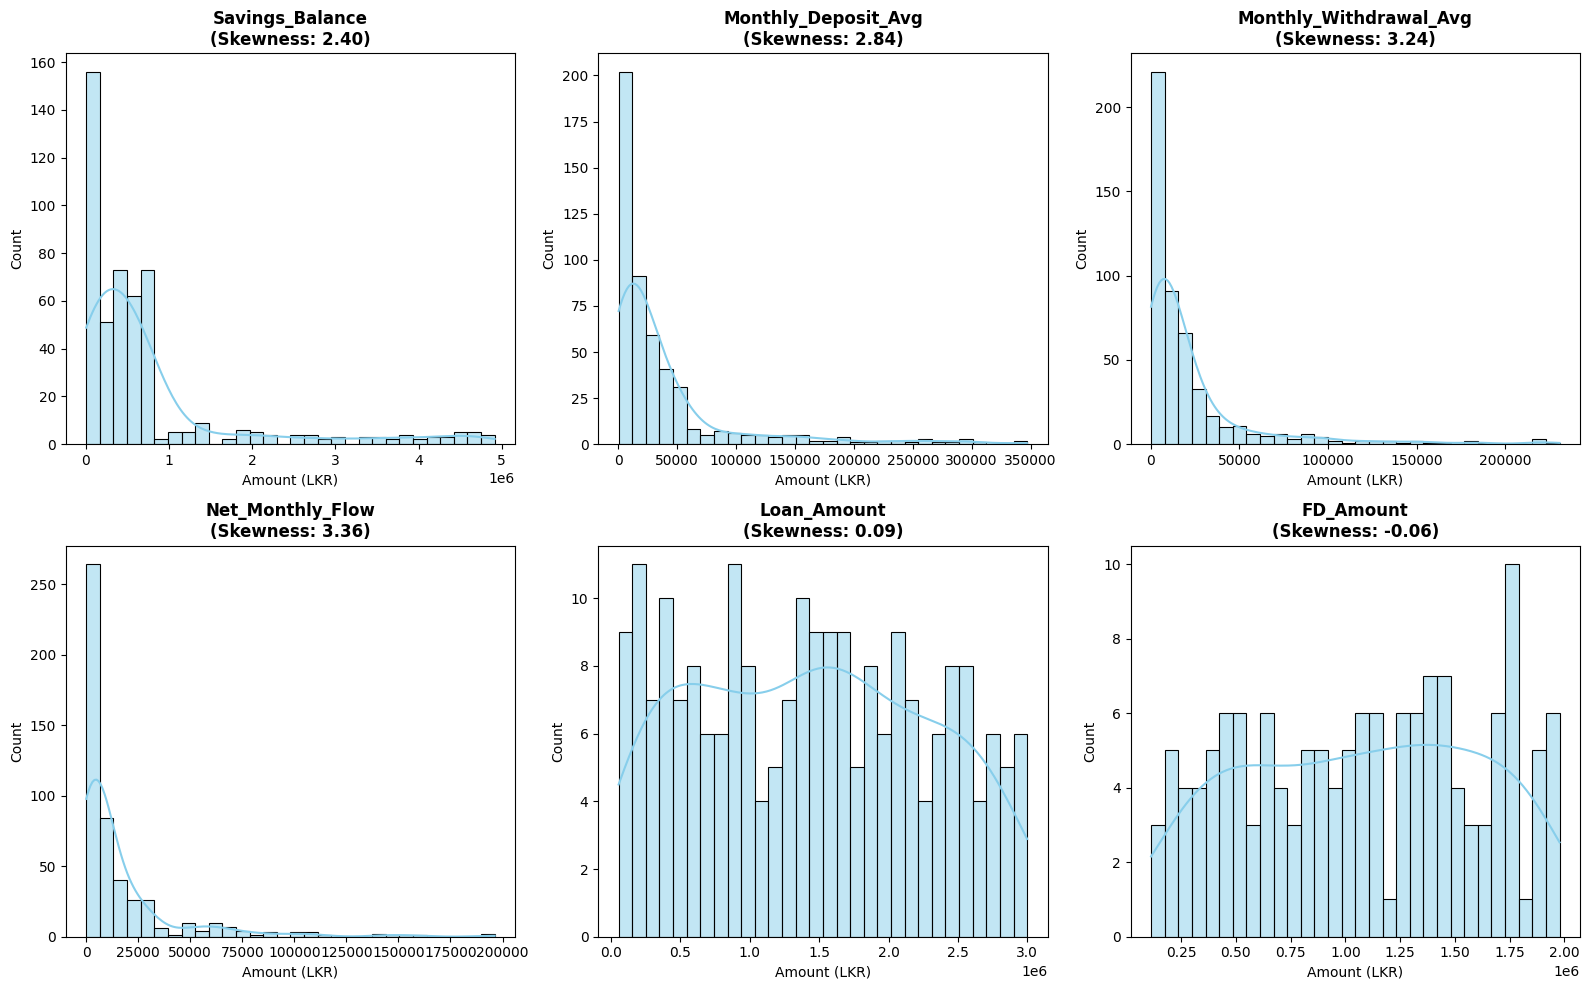

In [658]:
money_cols = ['Savings_Balance', 'Monthly_Deposit_Avg', 'Monthly_Withdrawal_Avg', 'Net_Monthly_Flow', 'Loan_Amount', 'FD_Amount']

plt.figure(figsize=(16, 10))
for i, col in enumerate(money_cols, 1):
    plt.subplot(2, 3, i)
    # Plot positive values to visualize operational money distributions clearly
    data_to_plot = data[data[col] > 0][col]
    sns.histplot(data_to_plot, kde=True, color='skyblue', bins=30)
    skewness = data_to_plot.skew()
    plt.title(f'{col}\n(Skewness: {skewness:.2f})', fontsize=12, fontweight='bold')
    plt.xlabel('Amount (LKR)', fontsize=10)
    plt.ylabel('Count', fontsize=10)

plt.tight_layout()
plt.show()

In [659]:
# Mapping of Sri Lankan Districts to their correct official Provinces
district_to_province = {
    'Colombo': 'Western', 'Gampaha': 'Western', 'Kalutara': 'Western',
    'Kandy': 'Central', 'Matale': 'Central', 'Nuwara Eliya': 'Central',
    'Galle': 'Southern', 'Matara': 'Southern', 'Hambantota': 'Southern',
    'Jaffna': 'Northern', 'Kilinochchi': 'Northern', 'Mannar': 'Northern', 'Vavuniya': 'Northern', 'Mullaitivu': 'Northern',
    'Trincomalee': 'Eastern', 'Batticaloa': 'Eastern', 'Ampara': 'Eastern',
    'Kurunegala': 'North Western', 'Puttalam': 'North Western',
    'Anuradhapura': 'North Central', 'Polonnaruwa': 'North Central',
    'Badulla': 'Uva', 'Moneragala': 'Uva',
    'Ratnapura': 'Sabaragamuwa', 'Kegalle': 'Sabaragamuwa'
}

# Update Province based on District
data['Province'] = data['District'].map(district_to_province).fillna(data['Province'])

In [660]:
data.columns

Index(['Customer_ID', 'Full_Name', 'NIC_Number', 'Gender', 'Date_of_Birth',
       'Age', 'District', 'Province', 'Urban_Rural', 'Customer_Segment',
       'Account_Open_Date', 'Customer_Tenure_Years', 'Savings_Balance',
       'Monthly_Deposit_Avg', 'Monthly_Withdrawal_Avg', 'Net_Monthly_Flow',
       'Account_Status', 'Interest_Rate_Tier', 'Has_Loan', 'Loan_Type',
       'Loan_Amount', 'Loan_Tenure_Months', 'Monthly_Repayment_Amount',
       'Loan_Repayment_Status', 'Loan_Start_Date', 'Outstanding_Loan_Balance',
       'Mobile_App_User', 'Last_Login_Date', 'Monthly_Transaction_Count',
       'Preferred_Channel', 'Push_Notification_Enabled', 'KYC_Status',
       'KYC_Last_Updated', 'Suspicious_Activity_Flag', 'PEP_Flag',
       'Has_Fixed_Deposit', 'FD_Amount', 'Has_Insurance', 'Has_Mobile_Wallet',
       'Number_of_Products', 'Acquisition_Channel', 'Referral_Source',
       'Last_Campaign_Response', 'Promo_Code_Used', 'Valid_NIC_Format'],
      dtype='object')

In [661]:
data.describe()

,Date_of_Birth,Age,Account_Open_Date,Customer_Tenure_Years,Savings_Balance,Monthly_Deposit_Avg,Monthly_Withdrawal_Avg,Net_Monthly_Flow,Loan_Amount,Loan_Tenure_Months,Monthly_Repayment_Amount,Loan_Start_Date,Outstanding_Loan_Balance,Last_Login_Date,Monthly_Transaction_Count,KYC_Last_Updated,FD_Amount,Number_of_Products
count,500,500.0,500,500.000000,5.000000e+02,500.000000,500.000000,500.000000,2.180000e+02,218.00000,218.000000,218,2.180000e+02,332,500.000000,500,1.450000e+02,500.000000
mean,1986-12-12 14:18:14.400000,36.56,2019-08-04 08:06:43.200000256,4.434800,7.686143e+05,38122.890300,22037.252620,16085.637680,1.427705e+06,34.12844,66446.899312,2021-10-25 21:21:28.073394432,7.699788e+05,2023-09-28 13:39:45.542168576,12.786000,2022-01-24 23:22:33.599999744,1.074669e+06,1.484000
min,1970-01-18 00:00:00,21.0,2015-01-14 00:00:00,0.000000,5.945010e+03,194.790000,100.990000,30.870000,5.430853e+04,12.00000,1008.140000,2012-06-15 00:00:00,1.625884e+04,2023-06-01 00:00:00,0.000000,2020-01-07 00:00:00,1.132178e+05,0.000000
25%,1978-06-15 18:00:00,28.0,2017-02-21 00:00:00,2.200000,1.274139e+05,5758.960000,3230.255000,1953.555000,7.096586e+05,12.00000,20592.450000,2020-08-22 12:00:00,2.339746e+05,2023-08-01 18:00:00,3.000000,2021-01-29 18:00:00,6.316680e+05,1.000000
50%,1987-01-31 00:00:00,36.0,2019-09-11 00:00:00,4.300000,4.465389e+05,17858.540000,9593.690000,6044.870000,1.431862e+06,36.00000,47278.575000,2022-06-30 00:00:00,6.712288e+05,2023-09-20 00:00:00,9.000000,2021-12-28 12:00:00,1.101161e+06,1.000000
75%,1995-05-28 00:00:00,45.0,2021-11-03 00:00:00,6.900000,7.283355e+05,40721.177500,22889.240000,17196.790000,2.109643e+06,48.00000,82529.862500,2023-06-05 00:00:00,1.191630e+06,2023-11-11 00:00:00,22.000000,2023-02-28 06:00:00,1.501144e+06,2.000000
max,2002-12-29 00:00:00,53.0,2026-06-01 00:00:00,9.000000,4.916005e+06,347140.120000,230688.560000,196240.990000,2.998363e+06,60.00000,274849.530000,2023-12-31 00:00:00,2.460698e+06,2027-01-01 00:00:00,35.000000,2024-01-01 00:00:00,1.977886e+06,4.000000
std,NaN,9.689074,NaN,2.631966,1.082795e+06,58017.651982,34962.647569,26953.742972,8.453553e+05,17.48474,64127.945546,NaN,5.917247e+05,NaN,10.862236,NaN,5.348230e+05,0.929231


In [662]:
# Number_of_Products = savings account (every customer has one) + each product flag that is 'Yes'
product_flags = ['Has_Loan', 'Has_Fixed_Deposit', 'Has_Insurance', 'Has_Mobile_Wallet']

data['Number_of_Products'] = 1 + (data[product_flags] == 'Yes').sum(axis=1)

# Sanity checks
print(data['Number_of_Products'].value_counts().sort_index())
print(data['Number_of_Products'].min(), data['Number_of_Products'].max())  # expect 1 and 5

Number_of_Products
1     74
2    183
3    174
4     64
5      5
Name: count, dtype: int64
1 5


In [663]:
# ---- Fix 1: restore the 5 valid savings balances + re-assign their segments ----
true_savings = {
    'FSL-0029': 299601.41,
    'FSL-0093': 536706.26,
    'FSL-0169': 1373070.11,
    'FSL-0276': 113054.03,
    'FSL-0401': 199730.37,
}
for cid, bal in true_savings.items():
    data.loc[data['Customer_ID'] == cid, 'Savings_Balance'] = bal

def segment_from_savings(bal, tier):
    if bal > 800000 and tier == 'Gold':
        return 'Premium'
    if bal > 150000:
        return 'Regular'
    return 'Starter' if tier == 'Standard' else 'Regular'

for cid in true_savings:
    m = data['Customer_ID'] == cid
    data.loc[m, 'Customer_Segment'] = segment_from_savings(
        data.loc[m, 'Savings_Balance'].iloc[0], data.loc[m, 'Interest_Rate_Tier'].iloc[0])

# ---- Fix 2: better imputation for the 11 genuinely unknown balances ----
unknown_ids = ['FSL-0023','FSL-0031','FSL-0056','FSL-0076','FSL-0100','FSL-0141',
               'FSL-0176','FSL-0196','FSL-0291','FSL-0321','FSL-0381']
affected = unknown_ids + list(true_savings)
is_unknown = data['Customer_ID'].isin(unknown_ids)
data['Savings_Imputed'] = np.where(is_unknown, 'Yes', 'No')

# median of Segment x Tier, calculated only from rows that were NOT touched
ref = data[~data['Customer_ID'].isin(affected)]
med = ref.groupby(['Customer_Segment', 'Interest_Rate_Tier'])['Savings_Balance'].median()
for i in data.index[is_unknown]:
    data.loc[i, 'Savings_Balance'] = med[(data.loc[i, 'Customer_Segment'],
                                          data.loc[i, 'Interest_Rate_Tier'])]

# ---- Check ----
chk = ['Customer_ID','Customer_Segment','Interest_Rate_Tier','Savings_Balance','Savings_Imputed']
print(data[data['Customer_ID'].isin(affected)][chk].to_string())
print(pd.crosstab(data['Customer_Segment'], data['Interest_Rate_Tier']))

    Customer_ID Customer_Segment Interest_Rate_Tier  Savings_Balance Savings_Imputed
22     FSL-0023          Regular             Silver       533161.770             Yes
28     FSL-0029          Regular             Silver       299601.410              No
30     FSL-0031          Regular             Silver       533161.770             Yes
55     FSL-0056          Regular             Silver       533161.770             Yes
75     FSL-0076          Regular           Standard        91139.265             Yes
92     FSL-0093          Regular             Silver       536706.260              No
99     FSL-0100          Premium               Gold      2698415.620             Yes
140    FSL-0141          Starter           Standard        85217.430             Yes
168    FSL-0169          Premium               Gold      1373070.110              No
175    FSL-0176          Regular             Silver       533161.770             Yes
195    FSL-0196          Regular             Silver       533161.

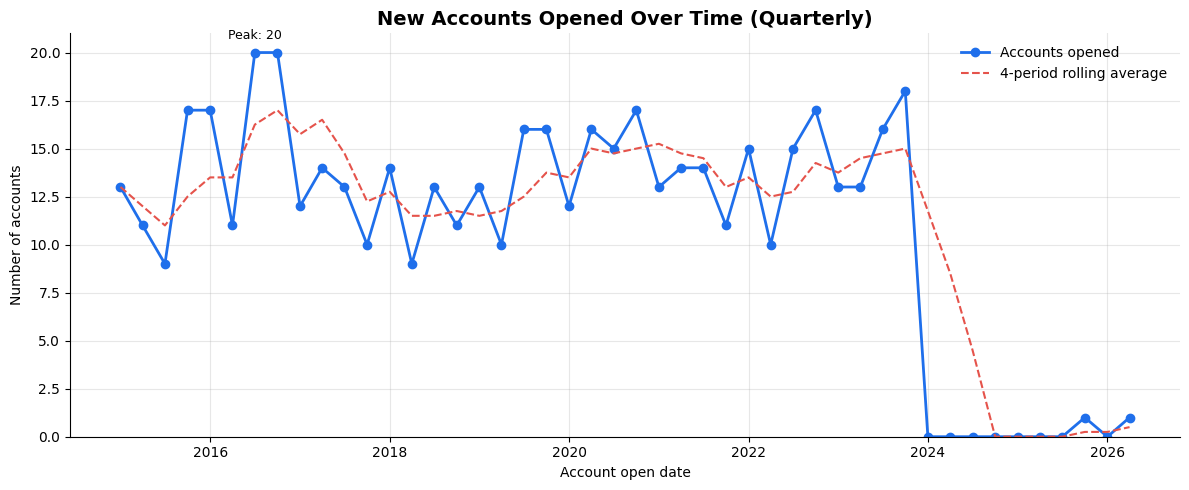

Total accounts: 500 | Period: 2015-01-14 to 2026-06-01
Account_Open_Date
2015    50
2016    68
2017    49
2018    47
2019    55
2020    60
2021    52
2022    57
2023    60
2025     1
2026     1


In [664]:
import pandas as pd
import matplotlib.pyplot as plt

data['Account_Open_Date'] = pd.to_datetime(data['Account_Open_Date'], errors='coerce')

# Accounts opened per period (500 rows is thin for monthly lines, ~4-5 per month)
freq = 'Q'          # 'Q' = quarterly, 'M' = monthly, 'Y' = yearly
period = data['Account_Open_Date'].dt.to_period(freq)
full = pd.period_range(period.min(), period.max(), freq=freq)       # keeps periods with 0 accounts
counts = period.value_counts().reindex(full, fill_value=0).sort_index()
counts.index = counts.index.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(counts.index, counts.values, marker='o', linewidth=2, color='#1f6feb', label='Accounts opened')
ax.plot(counts.index, counts.rolling(4, min_periods=1).mean(), linestyle='--', color='#e5534b',
        label='4-period rolling average')

peak = counts.idxmax()
ax.annotate(f'Peak: {counts.max()}', (peak, counts.max()), textcoords='offset points',
            xytext=(0, 10), ha='center', fontsize=9)

ax.set_title('New Accounts Opened Over Time (Quarterly)', fontsize=14, weight='bold')
ax.set_xlabel('Account open date')
ax.set_ylabel('Number of accounts')
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print(f"Total accounts: {counts.sum()} | Period: {data['Account_Open_Date'].min().date()} to {data['Account_Open_Date'].max().date()}")
print(data['Account_Open_Date'].dt.year.value_counts().sort_index().to_string())

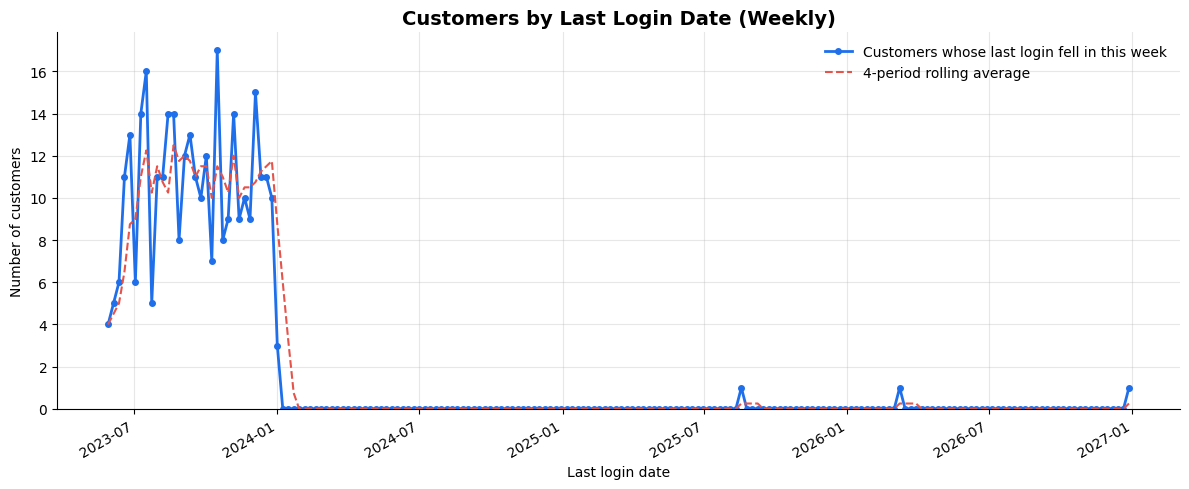

Customers with a login date: 332 of 500 | Range: 2023-06-01 to 2027-01-01
Last_Login_Date
2023-06    33
2023-07    49
2023-08    54
2023-09    44
2023-10    50
2023-11    46
2023-12    50
2024-01     3
2025-08     1
2026-03     1
2027-01     1
Freq: M


In [665]:
import pandas as pd
import matplotlib.pyplot as plt

data['Last_Login_Date'] = pd.to_datetime(data['Last_Login_Date'], errors='coerce')
logins = data['Last_Login_Date'].dropna()          # customers with no login are excluded

freq = 'W'          # 'W' = weekly, 'M' = monthly, 'D' = daily
period = logins.dt.to_period(freq)
full = pd.period_range(period.min(), period.max(), freq=freq)       # keeps periods with 0 customers
counts = period.value_counts().reindex(full, fill_value=0).sort_index()
counts.index = counts.index.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(counts.index, counts.values, marker='o', markersize=4, linewidth=2, color='#1f6feb',
        label='Customers whose last login fell in this week')
ax.plot(counts.index, counts.rolling(4, min_periods=1).mean(), linestyle='--', color='#e5534b',
        label='4-period rolling average')

ax.set_title('Customers by Last Login Date (Weekly)', fontsize=14, weight='bold')
ax.set_xlabel('Last login date')
ax.set_ylabel('Number of customers')
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

print(f"Customers with a login date: {len(logins)} of {len(data)} | Range: {logins.min().date()} to {logins.max().date()}")
print(logins.dt.to_period('M').value_counts().sort_index().to_string())

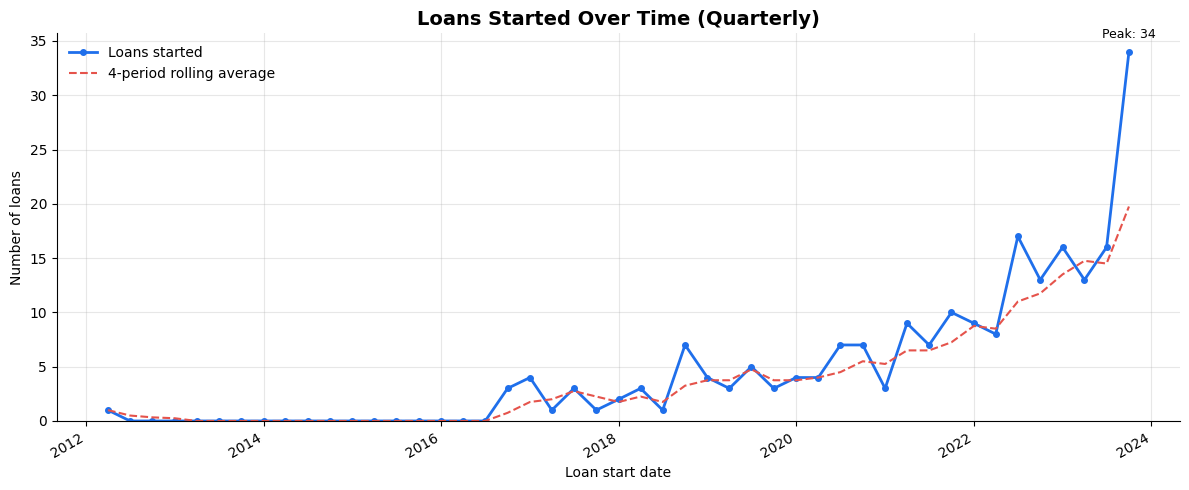

Loans with a start date: 218 of 218 loan customers | Range: 2012-06-15 to 2023-12-31
Loan_Start_Date
2012     1
2016     3
2017     9
2018    13
2019    15
2020    22
2021    29
2022    47
2023    79


In [666]:
import pandas as pd
import matplotlib.pyplot as plt

data['Loan_Start_Date'] = pd.to_datetime(data['Loan_Start_Date'], errors='coerce')
loans = data['Loan_Start_Date'].dropna()           # customers without a loan (or a blanked date) are excluded

freq = 'Q'          # 'Q' = quarterly, 'M' = monthly, 'Y' = yearly
period = loans.dt.to_period(freq)
full = pd.period_range(period.min(), period.max(), freq=freq)       # keeps periods with 0 loans
counts = period.value_counts().reindex(full, fill_value=0).sort_index()
counts.index = counts.index.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(counts.index, counts.values, marker='o', markersize=4, linewidth=2, color='#1f6feb',
        label='Loans started')
ax.plot(counts.index, counts.rolling(4, min_periods=1).mean(), linestyle='--', color='#e5534b',
        label='4-period rolling average')

peak = counts.idxmax()
ax.annotate(f'Peak: {counts.max()}', (peak, counts.max()), textcoords='offset points',
            xytext=(0, 10), ha='center', fontsize=9)

ax.set_title('Loans Started Over Time (Quarterly)', fontsize=14, weight='bold')
ax.set_xlabel('Loan start date')
ax.set_ylabel('Number of loans')
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

print(f"Loans with a start date: {len(loans)} of {data['Has_Loan'].eq('Yes').sum()} loan customers | Range: {loans.min().date()} to {loans.max().date()}")
print(loans.dt.year.value_counts().sort_index().to_string())

In [667]:
# ============================================================
# CELL 1 - VIEW the date problems (read-only, changes nothing)
# ============================================================
import pandas as pd
import numpy as np

date_cols = ['Account_Open_Date', 'Loan_Start_Date', 'Last_Login_Date', 'KYC_Last_Updated']
for c in date_cols:
    data[c] = pd.to_datetime(data[c], errors='coerce')

# 1) Find the data's "as-of" date from the data itself.
#    Customer_Tenure_Years ~= (as-of date - Account_Open_Date) / 365.25,
#    so Open_Date + Tenure should land on the same day for every clean row.
implied_asof = data['Account_Open_Date'] + pd.to_timedelta(data['Customer_Tenure_Years'] * 365.25, unit='D')
ASOF = implied_asof.median().round('D')   # nearest whole day (2024-01-01 in this data)
print("Implied as-of (snapshot) date from tenure:", ASOF.date())
print("Latest Loan_Start_Date:", data['Loan_Start_Date'].max().date(),
      "| Latest KYC_Last_Updated:", data['KYC_Last_Updated'].max().date())

show = ['Customer_ID', 'Account_Open_Date', 'Customer_Tenure_Years', 'Loan_Start_Date',
        'Last_Login_Date', 'Mobile_App_User', 'Account_Status']

# 2) Logins after the as-of date
bad_login = data['Last_Login_Date'] > ASOF
print(f"\n[A] Last_Login_Date after {ASOF.date()}: {bad_login.sum()} rows")
display(data.loc[bad_login, show])

# 3) Accounts opened after the as-of date
bad_open = data['Account_Open_Date'] > ASOF
print(f"\n[B] Account_Open_Date after {ASOF.date()}: {bad_open.sum()} rows")
display(data.loc[bad_open, show])

# 4) Tenure that disagrees with the open date (catches future dates AND subtler errors)
tenure_from_date = (ASOF - data['Account_Open_Date']).dt.days / 365.25
tenure_gap = (tenure_from_date - data['Customer_Tenure_Years']).abs()
bad_tenure = tenure_gap > 0.2
print(f"\n[C] Open date contradicts Customer_Tenure_Years (gap > 0.2 yr): {bad_tenure.sum()} rows")
display(data.loc[bad_tenure, show].assign(Tenure_From_Date=tenure_from_date[bad_tenure].round(1)))

# 5) Loan starting before the account existed, or before any account in the dataset
loan_before_any = data['Loan_Start_Date'] < data['Account_Open_Date'].min()
print(f"[D] Loan_Start_Date before the earliest account in the dataset ({data['Account_Open_Date'].min().date()}): {loan_before_any.sum()} rows")
display(data.loc[loan_before_open | loan_before_any,
                 ['Customer_ID', 'Account_Open_Date', 'Customer_Tenure_Years', 'Loan_Start_Date',
                  'Loan_Amount', 'Loan_Tenure_Months', 'Outstanding_Loan_Balance', 'Loan_Repayment_Status']])


Implied as-of (snapshot) date from tenure: 2024-01-01
Latest Loan_Start_Date: 2023-12-31 | Latest KYC_Last_Updated: 2024-01-01

[A] Last_Login_Date after 2024-01-01: 3 rows


,Customer_ID,Account_Open_Date,Customer_Tenure_Years,Loan_Start_Date,Last_Login_Date,Mobile_App_User,Account_Status
80,FSL-0081,2018-07-06,5.5,NaT,2026-03-15,Yes,Active
200,FSL-0201,2020-05-22,3.6,NaT,2025-08-20,Yes,Active
440,FSL-0441,2017-01-11,7.0,2022-05-31,2027-01-01,Yes,Active



[B] Account_Open_Date after 2024-01-01: 2 rows


,Customer_ID,Account_Open_Date,Customer_Tenure_Years,Loan_Start_Date,Last_Login_Date,Mobile_App_User,Account_Status
135,FSL-0136,2026-06-01,0.5,NaT,2023-08-18,Yes,Active
415,FSL-0416,2025-11-30,6.9,2018-03-21,2023-07-27,Yes,Active



[C] Open date contradicts Customer_Tenure_Years (gap > 0.2 yr): 2 rows


,Customer_ID,Account_Open_Date,Customer_Tenure_Years,Loan_Start_Date,Last_Login_Date,Mobile_App_User,Account_Status,Tenure_From_Date
135,FSL-0136,2026-06-01,0.5,NaT,2023-08-18,Yes,Active,-2.4
415,FSL-0416,2025-11-30,6.9,2018-03-21,2023-07-27,Yes,Active,-1.9


[D] Loan_Start_Date before the earliest account in the dataset (2015-01-14): 1 rows


,Customer_ID,Account_Open_Date,Customer_Tenure_Years,Loan_Start_Date,Loan_Amount,Loan_Tenure_Months,Outstanding_Loan_Balance,Loan_Repayment_Status
115,FSL-0116,2016-04-08,7.7,2012-06-15,2416681.11,48.0,1842211.00,On-Time
415,FSL-0416,2025-11-30,6.9,2018-03-21,1550799.47,12.0,757796.13,Defaulted


In [668]:

# Define snapshot date
ASOF_DATE = pd.to_datetime('2024-01-01')

# Case [A]: Set future Last_Login_Date to NaT
data.loc[data['Last_Login_Date'] > ASOF_DATE, 'Last_Login_Date'] = pd.NaT

# Case [B]: Recalculate Account_Open_Date from tenure (2024-01-01 minus Customer_Tenure_Years)
bad_open_mask = data['Account_Open_Date'] > ASOF_DATE
data.loc[bad_open_mask, 'Account_Open_Date'] = ASOF_DATE - pd.to_timedelta(
    data.loc[bad_open_mask, 'Customer_Tenure_Years'] * 365.25, unit='D'
)

# Case [C]: Set Account_Open_Date to NaT where open date contradicts tenure gap > 0.2 yrs
tenure_from_date = (ASOF_DATE - data['Account_Open_Date']).dt.days / 365.25
bad_tenure_mask = (tenure_from_date - data['Customer_Tenure_Years']).abs() > 0.2
data.loc[bad_tenure_mask, 'Account_Open_Date'] = pd.NaT

# Case [D]: Set Loan_Start_Date to NaT for FSL-0116 specifically
data.loc[data['Customer_ID'] == 'FSL-0116', 'Loan_Start_Date'] = pd.NaT

In [669]:
import numpy as np
import pandas as pd

# Ensure date columns are datetime type
data['Date_of_Birth'] = pd.to_datetime(data['Date_of_Birth'], errors='coerce')
data['Account_Open_Date'] = pd.to_datetime(
    data['Account_Open_Date'], errors='coerce'
)

# 1. Calculate Age at Account Opening (in exact years)
age_at_opening = (
    data['Account_Open_Date'] - data['Date_of_Birth']
).dt.days / 365.25

# 2. Binary Yes/No Status
# 'Yes' = Confirmed adult (Age >= 18)
# 'No'  = Questionable / Unverified (Age < 18 or missing/NaT date)
data['Verified_Adult_Account'] = np.where(age_at_opening >= 18, 'Yes', 'No')

In [670]:
import pandas as pd
import numpy as np

# Ensure dates are datetime format
data['Loan_Start_Date'] = pd.to_datetime(data['Loan_Start_Date'], errors='coerce')
ASOF_DATE = pd.to_datetime('2024-01-01')

# 1. Calculate the Expected Loan Maturity/End Date
loan_end_date = data['Loan_Start_Date'] + pd.to_timedelta(
    data['Loan_Tenure_Months'] * 30.4375, unit='D'
)

# 2. Condition: Past maturity date AND still owes money (> 0 balance)
is_past_term_with_balance = (loan_end_date < ASOF_DATE) & (
    data['Outstanding_Loan_Balance'] > 0
)

# 3. Create Loan_Verified Flag Column
# 'Yes' = Clean / Verified loan
# 'No'  = Questionable / Unverified loan (Past term yet still owes money)
data['Loan_Verified'] = np.where(is_past_term_with_balance, 'No', 'Yes')

# -------------------------------------------------------------------------
# VIEW RESULTS
# -------------------------------------------------------------------------

# Display overall counts (Should show 75 'No' and rest 'Yes')
print(data['Loan_Verified'].value_counts())

# View all unverified loans ('No')
cols_to_view = [
    'Customer_ID',
    'Loan_Start_Date',
    'Loan_Tenure_Months',
    'Outstanding_Loan_Balance',
    'Loan_Repayment_Status',
    'Loan_Verified',
]
unverified_loans_df = data.loc[data['Loan_Verified'] == 'No', cols_to_view]

display(unverified_loans_df)

Loan_Verified
Yes    426
No      74
Name: count, dtype: int64


,Customer_ID,Loan_Start_Date,Loan_Tenure_Months,Outstanding_Loan_Balance,Loan_Repayment_Status,Loan_Verified
3,FSL-0004,2022-09-29,12.0,1518451.26,Delayed,No
13,FSL-0014,2021-05-26,24.0,838393.34,Delayed,No
21,FSL-0022,2019-08-04,12.0,551780.79,On-Time,No
24,FSL-0025,2020-07-06,36.0,1659316.26,Delayed,No
25,FSL-0026,2017-08-19,12.0,826525.09,On-Time,No
...,...,...,...,...,...,...
477,FSL-0478,2022-09-05,12.0,220005.03,Defaulted,No
478,FSL-0479,2017-01-03,36.0,896456.69,On-Time,No
481,FSL-0482,2018-10-16,48.0,739557.51,On-Time,No
492,FSL-0493,2016-12-22,60.0,138490.74,On-Time,No


In [671]:
# Ensure date columns are in datetime format
data['Account_Open_Date'] = pd.to_datetime(data['Account_Open_Date'], errors='coerce')
data['KYC_Last_Updated'] = pd.to_datetime(data['KYC_Last_Updated'], errors='coerce')

# -------------------------------------------------------------------------
# Issue 1: 122 customers with KYC updated BEFORE Account Open Date
# -------------------------------------------------------------------------
kyc_before_open_mask = data['KYC_Last_Updated'] < data['Account_Open_Date']

print(f"Total customers with KYC updated before account open date: {kyc_before_open_mask.sum()}")

kyc_before_open_df = data.loc[
    kyc_before_open_mask,
    ['Customer_ID', 'Account_Open_Date', 'KYC_Last_Updated', 'KYC_Status']
]

display(kyc_before_open_df)

Total customers with KYC updated before account open date: 122


,Customer_ID,Account_Open_Date,KYC_Last_Updated,KYC_Status
0,FSL-0001,2021-02-11,2020-01-14,Verified
7,FSL-0008,2023-05-22,2021-04-26,Verified
8,FSL-0009,2022-03-28,2020-09-28,Verified
10,FSL-0011,2023-12-05,2020-11-28,Verified
12,FSL-0013,2021-10-19,2020-09-12,Verified
...,...,...,...,...
486,FSL-0487,2023-11-15,2022-04-23,Verified
491,FSL-0492,2022-02-22,2020-06-23,Verified
493,FSL-0494,2021-12-06,2020-04-06,Verified
495,FSL-0496,2023-07-01,2020-02-17,Expired


In [672]:
import pandas as pd

# Ensure date columns are in datetime format
data['Account_Open_Date'] = pd.to_datetime(data['Account_Open_Date'], errors='coerce')
data['KYC_Last_Updated'] = pd.to_datetime(data['KYC_Last_Updated'], errors='coerce')

# 1. Identify rows where KYC_Last_Updated is BEFORE Account_Open_Date
kyc_before_open_mask = data['KYC_Last_Updated'] < data['Account_Open_Date']

# 2. Null out the KYC date (set to NaT) for these rows
data.loc[kyc_before_open_mask, 'KYC_Last_Updated'] = pd.NaT

# 3. Update KYC_Status to 'Unknown' for these rows
data.loc[kyc_before_open_mask, 'KYC_Status'] = 'Unknown'

# -------------------------------------------------------------------------
# VERIFY RESULTS
# -------------------------------------------------------------------------

# View updated counts for KYC_Status
print(data['KYC_Status'].value_counts(dropna=False))

# Inspect the updated rows (KYC_Last_Updated should now show NaT and KYC_Status 'Unknown')
cols_to_view = ['Customer_ID', 'Account_Open_Date', 'KYC_Last_Updated', 'KYC_Status']
display(data.loc[kyc_before_open_mask, cols_to_view])

KYC_Status
Verified    263
Unknown     126
Expired      59
Pending      52
Name: count, dtype: int64


,Customer_ID,Account_Open_Date,KYC_Last_Updated,KYC_Status
0,FSL-0001,2021-02-11,NaT,Unknown
7,FSL-0008,2023-05-22,NaT,Unknown
8,FSL-0009,2022-03-28,NaT,Unknown
10,FSL-0011,2023-12-05,NaT,Unknown
12,FSL-0013,2021-10-19,NaT,Unknown
...,...,...,...,...
486,FSL-0487,2023-11-15,NaT,Unknown
491,FSL-0492,2022-02-22,NaT,Unknown
493,FSL-0494,2021-12-06,NaT,Unknown
495,FSL-0496,2023-07-01,NaT,Unknown


In [673]:
#Identification Violations (Missing NIC OR Duplicated NIC)

nic_missing_mask = data['NIC_Number'].isna() | (data['NIC_Number'].str.strip() == '')
data.loc[nic_missing_mask, 'KYC_Status'] = 'Unknown'
data.loc[nic_missing_mask, 'KYC_Last_Updated'] = pd.NaT

In [674]:
data = data.drop(columns=['Valid_NIC_Format'])

###Export

In [675]:
data.to_excel('/content/drive/MyDrive/FinSightAssessment/Working Files /Cleaned Data.xlsx', index=False)

In [676]:
data.shape

(500, 47)

In [677]:
data.columns

Index(['Customer_ID', 'Full_Name', 'NIC_Number', 'Gender', 'Date_of_Birth',
       'Age', 'District', 'Province', 'Urban_Rural', 'Customer_Segment',
       'Account_Open_Date', 'Customer_Tenure_Years', 'Savings_Balance',
       'Monthly_Deposit_Avg', 'Monthly_Withdrawal_Avg', 'Net_Monthly_Flow',
       'Account_Status', 'Interest_Rate_Tier', 'Has_Loan', 'Loan_Type',
       'Loan_Amount', 'Loan_Tenure_Months', 'Monthly_Repayment_Amount',
       'Loan_Repayment_Status', 'Loan_Start_Date', 'Outstanding_Loan_Balance',
       'Mobile_App_User', 'Last_Login_Date', 'Monthly_Transaction_Count',
       'Preferred_Channel', 'Push_Notification_Enabled', 'KYC_Status',
       'KYC_Last_Updated', 'Suspicious_Activity_Flag', 'PEP_Flag',
       'Has_Fixed_Deposit', 'FD_Amount', 'Has_Insurance', 'Has_Mobile_Wallet',
       'Number_of_Products', 'Acquisition_Channel', 'Referral_Source',
       'Last_Campaign_Response', 'Promo_Code_Used', 'Savings_Imputed',
       'Verified_Adult_Account', 'Loan_Verified

In [678]:
data['Savings_Imputed'].value_counts()

,count
Savings_Imputed,
No,489
Yes,11
